# COMET · biology figures (final)

Biology figures on the post-review COMET run (`comet/comet_outputs_post_review/`):
- **Figure 1 (revised)** (hema, paul15): lineage drivers rise in expression *and* gain regulatory weight in COMET's GRN.
- **Figure 1a** (hema, paul15): lineage TF expression, and the GRN edges that strengthen specifically along one lineage.
- **Figure 2** (AML 08H089): COMET's GRN rewires at the immature → blast0 transition, alongside a TF-wide switch and the HOX/MEIS programme.
- **Figure 2a / 2b** (AML): the rewiring burst with the TFs that change expression there (2b: panels a–b only).

**Pseudotime.** Every ordering in this notebook uses **COMET pseudotime**, computed exactly as in the benchmark figures:
`figures/new_metrics.velocity_pseudotime(zs(X), V_COMET, Z_decipher, how="potential")`.
Here `V_COMET` is the full COMET field: committor + chromatin lead + regulatory-consistency GRN tilt (λ = 0.5).
The old notebook ordered cells by the committor `committor_q`; that is **not** used anywhere here.
§1 checks the pseudotime against `figures/data/per_cell.csv`.

**GRN.** `A_base`, `A_dict` and `mix_weights` come from `comet/comet_outputs_post_review/` (the post-review run: no linear decoder, leak-free encoder, no coherence scaling of the chromatin lead, per-module target-access prior; the tilt sees each module's top 10% of edges, while the saved GRN stays dense). `V_pred.npy` there is the GRN-tilted field; `V_pred_grn_independent.npy` is the field before the tilt.

**Ground rules** (unchanged):
- cell-type labels name lineages and draw annotation bands; they never enter a score;
- known-regulator lists are fixed in the config cell, before any ranking;
- no TF→target edge claims are made (edges did not validate against CollecTRI; see `comet_bio_figures.ipynb` §2).

Outputs: `figs_final/`, `tables_final/`. Kernel: **Python (decipher)**.

## Figure 0 · combined Fig. 1a + Fig. 2b

Drawn in the last section (it needs every analysis above); shown here once the notebook has run.

![Figure 0](figs_final/fig0_combined.png)

In [1]:
# ── configuration ─────────────────────────────────────────────────────────────────────────────
import os, sys, numpy as np, pandas as pd
from scipy.stats import spearmanr, mannwhitneyu, binomtest
from scipy.ndimage import gaussian_filter1d

ROOT  = os.path.abspath("..")                                   # repo root (run from figures/)
COMET = f"{ROOT}/comet"
RF    = f"{COMET}/comet_outputs_post_review"                 # COMET run used throughout (GRN, field)
BENCH = f"{ROOT}/trajectory_benchmarking/recomb_bench"
OUT   = f"{ROOT}/figures"
FIG, TAB, CACHE = f"{OUT}/figs_final", f"{OUT}/tables_final", f"{OUT}/cache/bio_post_review"
for d in (FIG, TAB, CACHE): os.makedirs(d, exist_ok=True)
SEED, N_PERM, N_BOOT = 0, 2000, 200
MIN_DETECT = 0.05      # a TF is "expressed" if detected (>0) in ≥5% of cells; only expressed TFs are ranked

# lineages = ordered cell types from the root to one terminal fate (same definition as the benchmark)
LINEAGES = {"hema":   {"MEP": ["HSC", "MPP", "CMP", "MEP"], "GMP": ["HSC", "MPP", "CMP", "GMP"],
                       "MLP": ["HSC", "MPP", "MLP"]},
            "paul15": {"Ery": ["MEP", "Erythroids"], "Mk": ["MEP", "Megakaryocytes"],
                       "Gran": ["GMP", "late_GMP", "Granulocytes"], "Mono": ["GMP", "late_GMP", "Monocytes"]}}
# known lineage regulators, fixed BEFORE ranking (textbook hematopoiesis TFs); used only to evaluate rankings
KNOWN = {"hema":   {"MEP": ["GATA1", "KLF1", "TAL1", "GFI1B", "NFE2", "ZFPM1", "LMO2", "MYB"],
                    "GMP": ["SPI1", "CEBPA", "CEBPB", "CEBPE", "GFI1", "IRF8", "RUNX1"],
                    "MLP": ["IKZF1", "TCF3", "EBF1", "MEF2C", "LYL1", "HOXA9", "BCL11A"]},
         "paul15": {"Ery": ["Gata1", "Klf1", "Gfi1b", "Nfe2", "Zfpm1", "Tal1", "Myb"],
                    "Mk":  ["Fli1", "Gata1", "Runx1", "Gfi1b", "Pbx1"],
                    "Gran": ["Cebpa", "Cebpe", "Cebpb", "Gfi1", "Sfpi1"],
                    "Mono": ["Irf8", "Klf4", "Maf", "Mafb", "Cebpb", "Sfpi1"]}}
AML_STAGES = ["immature", "blast0", "blast1", "blast2", "blast3"]
AML_PROGRAM = ["HOXA9", "MEIS1", "PBX3", "HOXA10"]      # leukaemic HOX/MEIS programme highlighted in Fig. 2

In [2]:
# ── figure style ──────────────────────────────────────────────────────────────────────────────
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
mpl.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 6.5, "axes.titlesize": 7, "axes.titleweight": "bold", "axes.labelsize": 6.5,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.5,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2, "ytick.major.size": 2,
    "savefig.dpi": 300, "savefig.bbox": "tight", "pdf.fonttype": 42, "svg.fonttype": "none"})
COMET_C = "#c9027a"
HEAT = LinearSegmentedColormap.from_list("heat", ["#FFFFFF", "#FBE3EF", "#E77FB3", "#c9027a", "#5A0034"])
OUTC = LinearSegmentedColormap.from_list("outdeg", ["#1B7837", "#A6DBA0", "#F7F7F7", "#C2A5CF", "#762A83"])
MODC = LinearSegmentedColormap.from_list("mod", ["#F4F8F9", "#BFE0DD", "#5FB3AC", "#2A7F87", "#16455A"])
LIN_C = {"MEP": "#C8553D", "GMP": "#8E5A9C", "MLP": "#6A994E",
         "Ery": "#C8553D", "Mk": "#E9A03B", "Gran": "#8E5A9C", "Mono": "#4A7C9D"}
STAGE_C = {"immature": "#2D1E3E", "blast0": "#6B2D5C", "blast1": "#B0413E", "blast2": "#E07A3F", "blast3": "#F2B84B"}

def panel(ax, letter):
    ax.text(-0.02, 1.02, letter, transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="bottom")

## 1 · Data and COMET pseudotime

**Expression** comes from COMET's own loaders, which give the same cells, genes and TF vocabulary that the GRN was trained on. They are cached in `cache/<ds>_bundle.npz`.

**GRN.** It is per cell: $A_i = A_\text{base} + \sum_k w_{ik} A^{(k)}$, with 4 modules and per-cell weights $w_i$.

**COMET pseudotime** `pt` is computed by `figures/new_metrics.py`:
1. scVelo's velocity graph of the full COMET field, on a 30-NN graph in the Decipher latent;
2. its transition matrix;
3. the graph-flow (HodgeRank) potential, min-max scaled.

It is cached in `cache/pt_COMET_<ds>.npy` (delete the file to recompute) and checked against the benchmark's `figures/data/per_cell.csv`.

In [3]:
sys.path.insert(0, COMET); sys.path.insert(0, f"{ROOT}/figures")
import new_metrics as nm                                      # the benchmark's pseudotime: the one used everywhere

def comet_pseudotime(ds, force=False):
    f = f"{CACHE}/pt_COMET_{ds}.npy"
    if force or not os.path.exists(f):
        base = np.load(f"{nm.RB}/results/fields/{ds}_base.npz", allow_pickle=True)
        pt = nm.velocity_pseudotime(nm.zs(base["X"]), nm.comet_field(ds, base), base["Z_dec"].astype(np.float32),
                                    how="potential")
        np.save(f, pt)
    return np.load(f)

def load(ds, force=False):
    f = f"{CACHE}/{ds}_bundle.npz"
    if force or not os.path.exists(f):
        from config import BASES
        from data.load import LOADERS
        b = LOADERS[ds](BASES[ds])
        np.savez_compressed(f, X=b.X, X_TF=b.X_TF, genes=np.asarray(b.A_genes).astype(str),
                            tfs=np.asarray(b.A_tfs).astype(str), tf_idx=np.asarray(b.tf_indices_in_G),
                            M=b.M, obs_names=np.asarray(b.adata.obs_names).astype(str))
    c = dict(np.load(f, allow_pickle=True))
    r = {k: np.load(f"{RF}/{ds}/{k}.npy") for k in ["mix_weights", "A_base", "A_dict"]}
    lab = nm.load_obs(ds)                         # benchmark ground-truth labels (same cell order as COMET)
    assert (lab.index.values.astype(str) == c["obs_names"]).all(), "label table not in COMET cell order"
    assert (nm.load_obs(ds).index.astype(str).values == c["obs_names"]).all(), "pseudotime not in COMET cell order"
    pt = comet_pseudotime(ds); assert len(pt) == len(c["X"])
    d = dict(ds=ds, pt=pt, mix=r["mix_weights"], A_base=r["A_base"], A_dict=r["A_dict"],
             X=c["X"].astype(np.float32), XT=c["X_TF"].astype(np.float32), genes=c["genes"], tfs=c["tfs"],
             tf_idx=c["tf_idx"], M=c["M"], ct=lab.cell_type.astype(str).values, obs_names=c["obs_names"])
    d["expressed"] = (d["XT"] > 0).mean(0) >= MIN_DETECT
    return d

D = {ds: load(ds) for ds in ["hema", "paul15", "aml89"]}
pc = pd.read_csv(f"{ROOT}/figures/data/per_cell.csv")
for ds, d in D.items():
    p = pc[pc.dataset == ds].set_index("cell")["pt_COMET"]
    diff = np.abs(pd.Series(d["pt"], index=d["obs_names"]).reindex(p.index).values - p.values).max()
    assert diff < 1e-8, f"{ds}: pseudotime differs from figures/data/per_cell.csv"
    print(f"{ds:7s} {d['X'].shape[0]:5d} cells | {d['X'].shape[1]} genes | {len(d['tfs'])} TFs "
          f"({d['expressed'].sum()} expressed) | COMET pt matches per_cell.csv (max |diff| {diff:.1e}, {len(p)} cells)")

/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/anndata/_io/h5ad.py:267: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  return AnnData(**{
/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/anndata/_io/h5ad.py:267: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  return AnnData(**{


/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/anndata/_io/h5ad.py:192: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  adata = AnnData(**d)
/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/anndata/_io/h5ad.py:192: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  adata = AnnData(**d)


hema     1035 cells | 3016 genes | 277 TFs (238 expressed) | COMET pt matches per_cell.csv (max |diff| 1.1e-16, 1035 cells)
paul15   2671 cells | 1850 genes | 90 TFs (64 expressed) | COMET pt matches per_cell.csv (max |diff| 1.1e-16, 2671 cells)
aml89    5000 cells | 3198 genes | 785 TFs (293 expressed) | COMET pt matches per_cell.csv (max |diff| 1.1e-16, 3625 cells)


/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/anndata/_io/h5ad.py:192: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  adata = AnnData(**d)
/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/anndata/_io/h5ad.py:192: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  adata = AnnData(**d)


## 2 · Lineage drivers along COMET pseudotime

For lineage $L$ (root → one terminal fate) and an expressed TF $t$:
- **dynamics** $\rho_{t,L}$: Spearman correlation of $t$'s expression with COMET pseudotime, over $L$'s cells only;
- **specificity** $s_{t,L}$: mean expression in $L$'s terminal cells minus the *highest* mean among the other lineages' terminals, in units of the TF's s.d.;
- **driver score** $= \max(\rho,0)\cdot\max(s,0)$: high only if the TF rises along this lineage *and* ends higher here than in any other lineage.

The pre-listed regulators are scored by AUROC within each lineage's ranking, with a permutation p-value. The figure shows the top 3 drivers per lineage, whether or not they are known. `tables_final/drivers_<ds>.csv` has every TF's score.

In [4]:
def driver_table(d):
    rows = []
    for L, order in LINEAGES[d["ds"]].items():
        m = np.isin(d["ct"], order); term = order[-1]
        rho = np.array([spearmanr(d["XT"][m, t], d["pt"][m])[0] if d["expressed"][t] else np.nan
                        for t in range(len(d["tfs"]))])
        own = d["XT"][d["ct"] == term].mean(0)
        other = np.max([d["XT"][d["ct"] == o[-1]].mean(0) for k, o in LINEAGES[d["ds"]].items() if o[-1] != term], 0)
        spec = (own - other) / (d["XT"].std(0) + 1e-8)
        # a TF constant within this lineage has undefined rho: it is not dynamic here, so it scores 0
        score = np.where(d["expressed"], np.clip(np.nan_to_num(rho), 0, None) * np.clip(spec, 0, None), np.nan)
        rows.append(pd.DataFrame(dict(lineage=L, tf=d["tfs"], expressed=d["expressed"], rho_pseudotime=rho,
                                      specificity=spec, driver_score=score,
                                      known=np.isin(d["tfs"], KNOWN[d["ds"]][L]))))
    t = pd.concat(rows); t["rank"] = t.groupby("lineage").driver_score.rank(ascending=False, method="min")
    return t

def known_recovery(t, ds):
    rng = np.random.default_rng(SEED); out = []
    for L, g in t[t.expressed].groupby("lineage", sort=False):
        s = g.driver_score.values; k = g.known.values
        assert np.isfinite(s).all(), "driver scores must be finite for expressed TFs"
        auc = mannwhitneyu(s[k], s[~k]).statistic / (k.sum() * (~k).sum())
        null = np.array([mannwhitneyu(s[p], s[~p]).statistic / (p.sum() * (~p).sum())
                         for p in (np.isin(np.arange(len(s)), rng.choice(len(s), k.sum(), replace=False)) for _ in range(N_PERM))])
        out.append(dict(dataset=ds, lineage=L, n_known_expressed=int(k.sum()), AUROC=auc,
                        perm_p=(np.sum(null >= auc) + 1) / (N_PERM + 1),
                        known_in_top10=", ".join(g[k & (g["rank"] <= 10)].sort_values("rank").tf)))
    return pd.DataFrame(out)

DRV = {ds: driver_table(D[ds]) for ds in ["hema", "paul15"]}
REC = pd.concat([known_recovery(DRV[ds], ds) for ds in DRV])
for ds, t in DRV.items(): t.sort_values(["lineage", "rank"]).to_csv(f"{TAB}/drivers_{ds}.csv", index=False)
REC.to_csv(f"{TAB}/known_regulator_recovery.csv", index=False)
REC.round(3)

/tmp/ipykernel_96041/1000420930.py:5: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = np.array([spearmanr(d["XT"][m, t], d["pt"][m])[0] if d["expressed"][t] else np.nan


,dataset,lineage,n_known_expressed,AUROC,perm_p,known_in_top10
0,hema,MEP,3,0.576,0.180,GATA1
1,hema,GMP,5,0.899,0.000,"CEBPA, SPI1"
2,hema,MLP,4,0.689,0.034,MEF2C
0,paul15,Ery,5,0.685,0.083,"Klf1, Gfi1b, Gata1"
1,paul15,Mk,5,0.678,0.019,"Pbx1, Fli1, Gata1, Gfi1b, Runx1"
2,paul15,Gran,4,0.848,0.001,"Cebpe, Gfi1, Cebpa, Sfpi1"
3,paul15,Mono,2,0.992,0.001,"Irf8, Sfpi1"


In [5]:
# top drivers per lineage (unsupervised; ties to other lineages resolved by taking the next-ranked TF)
TOP_N = 3
def top_drivers(t, ds):
    used, sel = set(), []
    for L in LINEAGES[ds]:
        g = t[(t.lineage == L) & t.expressed].sort_values("driver_score", ascending=False)
        pick = [r for _, r in g.iterrows() if r.tf not in used][:TOP_N]
        for r in pick: used.add(r.tf); sel.append((L, r.tf, bool(r.known), r.driver_score))
    return sel
TOP = {ds: top_drivers(DRV[ds], ds) for ds in DRV}
for ds in TOP: print(ds, [(L, tf + ("★" if k else "")) for L, tf, k, _ in TOP[ds]])

hema [('MEP', 'GATA1★'), ('MEP', 'HES6'), ('MEP', 'MYC'), ('GMP', 'CEBPD'), ('GMP', 'CEBPA★'), ('GMP', 'FOSL2'), ('MLP', 'TCF4'), ('MLP', 'MEF2C★'), ('MLP', 'MEF2A')]
paul15 [('Ery', 'Klf1★'), ('Ery', 'Nfia'), ('Ery', 'E2f4'), ('Mk', 'Pbx1★'), ('Mk', 'Mef2c'), ('Mk', 'Runx2'), ('Gran', 'Cebpe★'), ('Gran', 'Gfi1★'), ('Gran', 'Nfic'), ('Mono', 'Irf8★'), ('Mono', 'Tcfec'), ('Mono', 'Sfpi1★')]


## 3 · Lineage-specific GRN modules (Fig. 1d)

- **Module usage.** For each lineage, the mean module weight $w_{ik}$ over its terminal cells. Each lineage's *own* module is the one most enriched in its terminal cells relative to all cells.
- **Regulator test.** TFs are ranked by **module-specific out-strength** in that module: $\sum_g |A^{(k)}_{gt}|$ minus the mean over the other modules. Subtracting the other modules removes the promiscuous-motif bias. The pre-listed regulators get an AUROC with a permutation p.

These use terminal cell types and the GRN only, not pseudotime, so they match the original notebook.

In [6]:
def module_table(d):
    K = d["A_dict"].shape[0]; out = np.abs(d["A_dict"]).sum(1)                  # (K, T) out-strength
    spec = out - (out.sum(0, keepdims=True) - out) / (K - 1)                      # module-specific out-strength
    rng = np.random.default_rng(SEED); rows = []
    for L, order in LINEAGES[d["ds"]].items():
        term = d["ct"] == order[-1]; use = d["mix"][term].mean(0)
        k = int(np.argmax(use - d["mix"].mean(0)))
        s = spec[k][d["expressed"]]; nm_ = d["tfs"][d["expressed"]]; kn = np.isin(nm_, KNOWN[d["ds"]][L])
        auc = mannwhitneyu(s[kn], s[~kn]).statistic / (kn.sum() * (~kn).sum())
        null = np.array([mannwhitneyu(s[p], s[~p]).statistic / (p.sum() * (~p).sum())
                         for p in (np.isin(np.arange(len(s)), rng.choice(len(s), kn.sum(), replace=False)) for _ in range(N_PERM))])
        best = [f"{nm_[i]} #{int((s > s[i]).sum()) + 1}" for i in np.where(kn)[0]]
        rows.append(dict(dataset=d["ds"], lineage=L, own_module=k + 1, **{f"M{j+1}": use[j] for j in range(K)},
                         AUROC=auc, perm_p=(np.sum(null >= auc) + 1) / (N_PERM + 1),
                         known_ranks="; ".join(sorted(best, key=lambda x: int(x.split('#')[1]))[:3])))
    return pd.DataFrame(rows)
MOD = pd.concat([module_table(D[ds]) for ds in ["hema", "paul15"]])
MOD.to_csv(f"{TAB}/module_lineage_specificity.csv", index=False); MOD.round(3)

,dataset,lineage,own_module,M1,M2,M3,M4,AUROC,perm_p,known_ranks
0,hema,MEP,2,0.017,0.578,0.130,0.275,0.543,0.413,NFE2 #20; GATA1 #92; MYB #216
1,hema,GMP,4,0.184,0.111,0.143,0.562,0.512,0.474,IRF8 #37; CEBPB #68; CEBPA #134
2,hema,MLP,3,0.158,0.182,0.396,0.263,0.775,0.030,MEF2C #4; IKZF1 #20; TCF3 #41
0,paul15,Ery,2,0.027,0.671,0.061,0.240,0.671,0.104,Klf1 #14; Gata1 #15; Myb #22
1,paul15,Mk,1,0.358,0.062,0.268,0.312,0.437,0.688,Gata1 #11; Gfi1b #22; Pbx1 #45
2,paul15,Gran,3,0.299,0.017,0.578,0.106,0.696,0.104,Sfpi1 #7; Cebpa #13; Gfi1 #30
3,paul15,Mono,3,0.251,0.020,0.628,0.101,0.919,0.022,Irf8 #6; Sfpi1 #7


## 4 · Do lineage drivers also gain regulatory weight in COMET's GRN? (TF hub score)

**Hub score** (a weighted out-degree). For TF $t$ in cell $i$: $o_{it} = \sum_g |A_{i,gt}|$, from that cell's own network $A_i$.

**Normalisation.**
- Take $\log(o_{it}/\bar o_t)$, relative to the TF's own mean, because the motif prior is dense and only *changes* are compared.
- Then subtract each cell's median over expressed TFs, which removes the shared per-cell rescaling from module mixing.

**Specificity.** $\Delta_{t,L}$ = the change of normalised hub score from $L$'s first stage to its terminal stage, minus the largest such change toward any other lineage's terminal.

**Tests.** Do the top-5 *expression* drivers (§2) and, separately, the pre-listed regulators rank high in $\Delta_{\cdot,L}$? AUROC with a permutation p.

**Caveat.** This is model-internal consistency, not external validation. The claim is that COMET's GRN assigns more regulatory weight to the lineage drivers in their own lineage, not that those TFs regulate more genes in vivo.

In [7]:
def weighted_outdegree(d):
    """(N, T) per-cell weighted out-degree sum_g |A_i[g,t]|; one (N,K)@(K,G) per TF, no (N,G,T) tensor."""
    O = np.zeros((len(d["pt"]), len(d["tfs"])), np.float32)
    for t in range(len(d["tfs"])):
        O[:, t] = np.abs(d["A_base"][:, t][None, :] + d["mix"] @ d["A_dict"][:, :, t]).sum(1)
    return O

OUTDEG = {ds: weighted_outdegree(D[ds]) for ds in ["hema", "paul15"]}
LOGOUT = {ds: np.log(O / O.mean(0)) for ds, O in OUTDEG.items()}            # relative to each TF's own mean
# remove the shared per-cell shift from module mixing (median over expressed TFs) so what remains is TF-specific
for ds in LOGOUT: LOGOUT[ds] = LOGOUT[ds] - np.median(LOGOUT[ds][:, D[ds]["expressed"]], axis=1, keepdims=True)

def outdegree_specificity(ds, n_top=5):
    d = D[ds]; L_ = LOGOUT[ds]; rng = np.random.default_rng(SEED); rows, per_tf = [], []
    for L, order in LINEAGES[ds].items():
        start = L_[d["ct"] == order[0]].mean(0)
        own = L_[d["ct"] == order[-1]].mean(0) - start
        other = np.max([L_[d["ct"] == o[-1]].mean(0) - start for k, o in LINEAGES[ds].items() if k != L], 0)
        spec = own - other
        g = DRV[ds][(DRV[ds].lineage == L) & DRV[ds].expressed].sort_values("driver_score", ascending=False)
        sets = {"top-5 expression drivers": g.tf.values[:n_top], "pre-listed regulators": g[g.known].tf.values}
        s = spec[d["expressed"]]; nm_ = d["tfs"][d["expressed"]]
        per_tf.append(pd.DataFrame(dict(lineage=L, tf=nm_, outdegree_specificity=s)))
        for name, sel in sets.items():
            isin = np.isin(nm_, sel)
            auc = mannwhitneyu(s[isin], s[~isin]).statistic / (isin.sum() * (~isin).sum())
            null = np.array([mannwhitneyu(s[p], s[~p]).statistic / (p.sum() * (~p).sum())
                             for p in (np.isin(np.arange(len(s)), rng.choice(len(s), isin.sum(), replace=False)) for _ in range(N_PERM))])
            rows.append(dict(dataset=ds, lineage=L, tf_set=name, n=int(isin.sum()), AUROC=auc,
                             perm_p=(np.sum(null >= auc) + 1) / (N_PERM + 1)))
    pd.concat(per_tf).sort_values(["lineage", "outdegree_specificity"], ascending=[True, False]).to_csv(
        f"{TAB}/outdegree_specificity_{ds}.csv", index=False)
    return pd.DataFrame(rows)

ODS = pd.concat([outdegree_specificity(ds) for ds in ["hema", "paul15"]])
ODS.to_csv(f"{TAB}/outdegree_driver_tests.csv", index=False); ODS.round(3)

,dataset,lineage,tf_set,n,AUROC,perm_p
0,hema,MEP,top-5 expression drivers,5,0.736,0.034
1,hema,MEP,pre-listed regulators,3,0.609,0.274
2,hema,GMP,top-5 expression drivers,5,0.269,0.964
3,hema,GMP,pre-listed regulators,5,0.439,0.676
4,hema,MLP,top-5 expression drivers,5,0.774,0.026
5,hema,MLP,pre-listed regulators,4,0.769,0.031
0,paul15,Ery,top-5 expression drivers,5,0.525,0.432
1,paul15,Ery,pre-listed regulators,5,0.651,0.136
2,paul15,Mk,top-5 expression drivers,5,0.681,0.090
3,paul15,Mk,pre-listed regulators,5,0.614,0.217


## Figure 1 (revised) · Lineage drivers rise in expression *and* gain regulatory weight in COMET's GRN

Rows are the unsupervised top-3 drivers per lineage (★ = pre-listed regulator). Columns are each lineage's cells ordered by **COMET pseudotime**: 10 equal-cell bins per lineage, Gaussian-smoothed (σ = 1 bin).
- **(a)** TF expression, each row scaled to its maximum over all lineages.
- **(b)** The same TFs' hub score in COMET's per-cell GRN (TF-specific log ratio). Purple = more regulatory weight, green = less; symmetric scale clipped at the 98th percentile of |value|.
- **(c)** Hub-score specificity tests (§4): AUROC of the top-5 expression drivers (●) and of the pre-listed regulators (◆). Filled = permutation p < 0.05; dashed line = chance.
- **(d)** Mean module weight in each lineage's terminal cells. The box marks the lineage's own module; the right column is the known-regulator enrichment in that module (AUROC, permutation p; bold = p < 0.05).

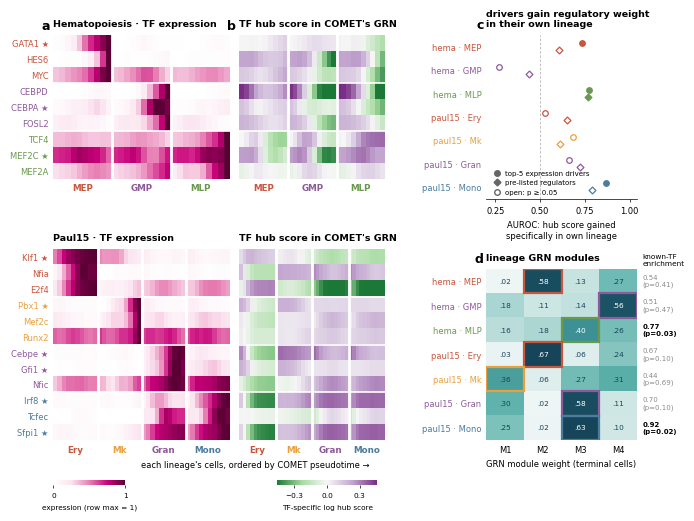

In [8]:
NB_LIN = 10
def lineage_profile_matrix(d, M, tfs_sel, scale="rowmax"):
    cols = []; idx = [list(d["tfs"]).index(t) for t in tfs_sel]
    for L, order in LINEAGES[d["ds"]].items():
        m = np.where(np.isin(d["ct"], order))[0]; o = m[np.argsort(d["pt"][m], kind="stable")]
        cols.append(gaussian_filter1d(np.array([M[b][:, idx].mean(0) for b in np.array_split(o, NB_LIN)]).T, 1.0, axis=1))
    P = np.concatenate(cols, 1)
    return P / (P.max(1, keepdims=True) + 1e-12) if scale == "rowmax" else P

def heat_blocks(ax, P, ds, cmap, norm=None, vmin=None, vmax=None, labels=True, star=True):
    sel = TOP[ds]; Ls = list(LINEAGES[ds])
    im = ax.imshow(P, aspect="auto", cmap=cmap, norm=norm, vmin=vmin, vmax=vmax, interpolation="nearest")
    for j in range(1, len(Ls)): ax.axvline(j * NB_LIN - 0.5, color="white", lw=2)
    for i in range(1, len(Ls)): ax.axhline(i * TOP_N - 0.5, color="white", lw=1.2)
    if labels:
        ax.set_yticks(range(len(sel)), [tf + (" ★" if k and star else "") for _, tf, k, _ in sel], fontsize=6)
        for t, (L, _, _, _) in zip(ax.get_yticklabels(), sel): t.set_color(LIN_C[L])
    else: ax.set_yticks([])
    ax.set_xticks([j * NB_LIN + NB_LIN / 2 - 0.5 for j in range(len(Ls))], Ls, fontsize=6.3)
    for t, L in zip(ax.get_xticklabels(), Ls): t.set_color(LIN_C[L]); t.set_fontweight("bold")
    ax.tick_params(length=0); [s_.set_visible(False) for s_ in ax.spines.values()]
    return im

fig = plt.figure(figsize=(7.2, 5.0))
outer = fig.add_gridspec(1, 2, width_ratios=[3.2, 1.45], wspace=0.42, left=0.09, right=0.90, top=0.92, bottom=0.11)
gs = outer[0].subgridspec(2, 2, width_ratios=[1.75, 1.45], height_ratios=[3, 4], wspace=0.06, hspace=0.42)
for r, ds in enumerate(["hema", "paul15"]):
    sel = [tf for _, tf, _, _ in TOP[ds]]; d = D[ds]
    ax = fig.add_subplot(gs[r, 0]); im_a = heat_blocks(ax, lineage_profile_matrix(d, d["XT"], sel), ds, HEAT, vmin=0, vmax=1)
    ax.set_title(("Hematopoiesis" if ds == "hema" else "Paul15") + " · TF expression", loc="left", fontsize=6.8)
    if r == 0: panel(ax, "a")
    P = lineage_profile_matrix(d, LOGOUT[ds], sel, scale=None); lim = np.percentile(np.abs(P), 98)
    axb = fig.add_subplot(gs[r, 1]); im_b = heat_blocks(axb, P, ds, OUTC, norm=TwoSlopeNorm(0, -lim, lim), labels=False)
    axb.set_title("TF hub score in COMET's GRN", loc="left", fontsize=6.8)
    if r == 0: panel(axb, "b")
fig.text(0.37, 0.055, "each lineage's cells, ordered by COMET pseudotime →", ha="center", fontsize=6)

gr = outer[1].subgridspec(2, 1, height_ratios=[1.0, 1.05], hspace=0.42)
axc = fig.add_subplot(gr[0]); panel(axc, "c")
ods = ODS.copy(); keys = list(dict.fromkeys(zip(ods.dataset, ods.lineage))); y = {k: i for i, k in enumerate(keys)}
axc.axvline(0.5, color="0.7", lw=0.6, ls=(0, (3, 2)))
for _, row in ods.iterrows():
    yi = y[(row.dataset, row.lineage)] + (-0.15 if row.tf_set.startswith("top") else 0.15)
    sig = row.perm_p < 0.05; mk = "o" if row.tf_set.startswith("top") else "D"
    axc.scatter(row.AUROC, yi, marker=mk, s=16 if mk == "o" else 12, color=LIN_C[row.lineage] if sig else "white",
                ec=LIN_C[row.lineage], lw=0.9, zorder=3)
axc.set_yticks(range(len(keys)), [f"{d_} · {L}" for d_, L in keys], fontsize=6)
for t, (_, L) in zip(axc.get_yticklabels(), keys): t.set_color(LIN_C[L])
axc.set_ylim(len(keys) - 0.5, -0.5); axc.set_xlim(0.2, 1.04); axc.set_xticks([0.25, 0.5, 0.75, 1.0])
axc.set_xlabel("AUROC: hub score gained\nspecifically in own lineage", fontsize=6)
axc.spines["left"].set_visible(False); axc.tick_params(axis="y", length=0)
axc.legend(handles=[Line2D([], [], ls="", marker="o", ms=4, mfc="0.4", mec="0.4", label="top-5 expression drivers"),
                    Line2D([], [], ls="", marker="D", ms=3.5, mfc="0.4", mec="0.4", label="pre-listed regulators"),
                    Line2D([], [], ls="", marker="o", ms=4, mfc="white", mec="0.4", label="open: p ≥ 0.05")],
           loc="lower left", fontsize=5.0, handletextpad=0.2, ncol=1, frameon=False, borderaxespad=0.1)
axc.set_title("drivers gain regulatory weight\nin their own lineage", loc="left", fontsize=6.8)

axd = fig.add_subplot(gr[1]); panel(axd, "d")
m = MOD.reset_index(drop=True); K = 4; Mv = m[[f"M{k+1}" for k in range(K)]].values
axd.imshow(Mv, aspect="auto", cmap=MODC, vmin=0, vmax=0.6)
for i, row in m.iterrows():
    for k in range(K):
        axd.text(k, i, f"{Mv[i, k]:.2f}".lstrip("0"), ha="center", va="center", fontsize=5.3, color="white" if Mv[i, k] > 0.38 else "#16455A")
    axd.add_patch(plt.Rectangle((row.own_module - 1.5, i - 0.5), 1, 1, fill=False, ec=LIN_C[row.lineage], lw=1.6))
    sig = row.perm_p < 0.05
    axd.text(K - 0.35, i, f"{row.AUROC:.2f}\n(p={row.perm_p:.2f})", va="center", fontsize=5.0,
             color="k" if sig else "0.55", fontweight="bold" if sig else None)
axd.set_xticks(range(K), [f"M{k+1}" for k in range(K)], fontsize=6)
axd.set_yticks(range(len(m)), [f"{d_} · {L}" for d_, L in zip(m.dataset, m.lineage)], fontsize=6)
for t, L in zip(axd.get_yticklabels(), m.lineage): t.set_color(LIN_C[L])
axd.text(K - 0.35, -0.6, "known-TF\nenrichment", fontsize=5.3, va="bottom")
axd.tick_params(length=0); [s_.set_visible(False) for s_ in axd.spines.values()]
axd.set_xlabel("GRN module weight (terminal cells)", fontsize=6)
axd.set_title("lineage GRN modules", loc="left", fontsize=6.8)

ca = fig.add_axes([0.09, 0.02, 0.10, 0.011]); cb = fig.colorbar(im_a, cax=ca, orientation="horizontal", ticks=[0, 1])
cb.set_label("expression (row max = 1)", fontsize=5.3); cb.ax.tick_params(labelsize=5.3); cb.outline.set_visible(False)
cb2 = fig.add_axes([0.40, 0.02, 0.14, 0.011]); c2 = fig.colorbar(im_b, cax=cb2, orientation="horizontal", ticks=[-0.3, 0, 0.3])
c2.set_label("TF-specific log hub score", fontsize=5.3); c2.ax.tick_params(labelsize=5.3); c2.outline.set_visible(False)
fig.savefig(f"{FIG}/fig1_revised_drivers_outdegree.pdf"); fig.savefig(f"{FIG}/fig1_revised_drivers_outdegree.png"); plt.show()

## 4b · Which regulatory interactions strengthen along one lineage more than along the competing lineages?

**Edge change along a lineage.** For lineage $L$, take its cells ordered by COMET pseudotime: *early* = the first quarter, *late* = the last quarter.
- Because $A_i = A_\text{base} + \sum_k w_{ik}A^{(k)}$, the mean change of edge $t\to g$ is exact: $\Delta A^{(L)}_{tg} = \sum_k(\bar w_{k,\mathrm{late}(L)} - \bar w_{k,\mathrm{early}(L)})\,A^{(k)}_{gt}$.
- We ask whether an edge gets *stronger*, so the change is signed by the edge's mean sign: $\Delta^{(L)}_{tg} = \mathrm{sign}(\bar A_{tg})\,\Delta A^{(L)}_{tg}$. Positive means an activating edge becomes more activating, or a repressive edge more repressive.

**Branch specificity.** $S^{(L)}_{tg} = \Delta^{(L)}_{tg} - \max_{L'\neq L}\Delta^{(L')}_{tg}$, used as a ranking statistic, not a test.

**Candidate edges.** All of the following must hold:
- $\Delta^{(L)} > 0$, a real strengthening along $L$, not just a smaller loss than elsewhere;
- $S^{(L)} > 0$;
- nonzero edge;
- target detected in ≥5% of cells;
- TF detected in ≥10% of $L$'s late cells;
- no self-edges.

**Unsupervised choice of what to draw.**
- **Branches:** those whose top $S$ is at least 25% of the dataset's largest. Weaker branches are at noise level and are listed but not drawn.
- **TF:** chosen from the lineage's own expression drivers in panel (a) (§2, top 3). Among them, the TF whose 3 strongest candidate edges have the largest summed $S$. So the hub is a TF that both rises in expression along the lineage *and* has branch-specific edge gains. The unrestricted ranking over all TFs is still printed, for comparison.
- **Edges:** that TF's candidate targets ranked by $S$ (up to 8; fewer if the TF has fewer candidate edges).
- Everything is printed and written to `tables_final/branch_edges_<ds>.csv` and `branch_tf_ranking.csv`.

**Caveat.** Per-cell networks are built from one shared base network and 4 modules, so these edge changes come entirely from the inferred module weights. They are not independent edge estimates. Targets of the same module move together, so many TFs share top targets. These are *inferred branch-associated regulatory changes*, consistent with, not proof of, lineage-specific regulation.

In [9]:
Q_EDGE, K_TGT, MIN_TF_LATE, NOISE_FRAC = 0.25, 8, 0.10, 0.25

def branch_edges(d):
    Abar = d["A_base"] + np.einsum("k,kgt->gt", d["mix"].mean(0), d["A_dict"]); sgn = np.sign(Abar)
    D, cells = {}, {}
    for L, order in LINEAGES[d["ds"]].items():
        idx = np.where(np.isin(d["ct"], order))[0]; idx = idx[np.argsort(d["pt"][idx], kind="stable")]
        n = int(len(idx) * Q_EDGE); cells[L] = (idx[:n], idx[-n:])
        D[L] = sgn * np.einsum("k,kgt->gt", d["mix"][idx[-n:]].mean(0) - d["mix"][idx[:n]].mean(0), d["A_dict"])
    gexpr = (d["X"] > 0).mean(0) >= MIN_DETECT; edges, ranks, info = [], [], []
    for L in D:
        early, late = cells[L]
        ok = (Abar != 0) & ((d["XT"][late] > 0).mean(0) >= MIN_TF_LATE)[None] & gexpr[:, None] & (D[L] > 0)
        ok[d["tf_idx"], np.arange(len(d["tfs"]))] = False
        S = D[L] - np.max([D[l] for l in D if l != L], 0); ok &= S > 0
        dx = d["X"][late].mean(0) - d["X"][early].mean(0)                      # target expression change (log)
        g, t = np.nonzero(ok)
        edges.append(pd.DataFrame(dict(dataset=d["ds"], lineage=L, tf=d["tfs"][t], target=d["genes"][g], S=S[g, t],
                                       strengthening=D[L][g, t], edge_mean=Abar[g, t], target_expr_change=dx[g])))
        Sm = np.where(ok, S, 0)
        ranks.append(pd.DataFrame(dict(dataset=d["ds"], lineage=L, tf=d["tfs"], topK_S=-np.sort(-Sm, axis=0)[:K_TGT].sum(0))))
        mode = lambda c: pd.Series(d["ct"][c]).value_counts().index[0]
        info.append(dict(dataset=d["ds"], lineage=L, n_edges=int(ok.sum()), max_S=float(Sm.max()),
                         early=mode(early), late=mode(late)))
    E = pd.concat(edges).sort_values(["lineage", "S"], ascending=[True, False]).reset_index(drop=True)
    R_ = pd.concat(ranks); R_ = R_[R_.topK_S > 0].sort_values(["lineage", "topK_S"], ascending=[True, False])
    return E, R_, pd.DataFrame(info)

BE = {ds: branch_edges(D[ds]) for ds in ["hema", "paul15"]}
EDGES = pd.concat([BE[ds][0] for ds in BE]); TFRANK = pd.concat([BE[ds][1] for ds in BE])
BINFO = pd.concat([BE[ds][2] for ds in BE]).reset_index(drop=True)
BINFO["drawn"] = BINFO.max_S >= NOISE_FRAC * BINFO.groupby("dataset").max_S.transform("max")
for ds in BE: BE[ds][0].groupby("lineage").head(500).to_csv(f"{TAB}/branch_edges_{ds}.csv", index=False)
TFRANK.groupby(["dataset", "lineage"]).head(30).to_csv(f"{TAB}/branch_tf_ranking.csv", index=False)
BINFO.round(4)

,dataset,lineage,n_edges,max_S,early,late,drawn
0,hema,MEP,26722,0.1576,MPP,MEP,True
1,hema,GMP,67753,0.2067,MPP,GMP,True
2,hema,MLP,30665,0.0790,MPP,MLP,True
3,paul15,Ery,20513,0.3851,MEP,Erythroids,True
4,paul15,Mk,1475,0.0204,MEP,Megakaryocytes,False
5,paul15,Gran,248,0.0033,GMP,Granulocytes,False
6,paul15,Mono,5987,0.0386,GMP,Monocytes,False


In [10]:
# everything behind the networks: per branch, the top 15 edges, and the top 8 TFs with their top-8 targets
pd.set_option("display.width", 200)
NETS = []
for _, b in BINFO.iterrows():
    e = EDGES[(EDGES.dataset == b.dataset) & (EDGES.lineage == b.lineage)]
    r = TFRANK[(TFRANK.dataset == b.dataset) & (TFRANK.lineage == b.lineage)]
    print(f"\n=== {b.dataset} · {b.lineage} ({b.early} → {b.late}) | {b.n_edges} candidate edges | max S {b.max_S:.3f} | "
          f"{'DRAWN' if b.drawn else 'not drawn (noise level)'}")
    print(e.head(15)[["tf", "target", "S", "strengthening", "edge_mean", "target_expr_change"]].round(3).to_string(index=False))
    for tf, sc in zip(r.tf.values[:8], r.topK_S.values[:8]):
        tg = e[e.tf == tf].head(K_TGT)
        print(f"  {tf:9s} top-{K_TGT} S sum {sc:.3f} | " + ", ".join(
            f"{g}{'+' if a > 0 else '−'}({s:.3f})" for g, a, s in zip(tg.target, tg.edge_mean, tg.S)))
    drv = [tf for L_, tf, *_ in TOP[b.dataset] if L_ == b.lineage]                  # panel (a) drivers of this lineage
    top3 = {tf: e[e.tf == tf].S.head(3).sum() for tf in drv}
    print("  panel-(a) drivers, sum of top-3 S:", {tf: round(v, 3) for tf, v in top3.items()},
          "| n candidate edges:", {tf: int((e.tf == tf).sum()) for tf in drv})
    if b.drawn and max(top3.values()) > 0:
        NETS.append((b.dataset, b.lineage, max(top3, key=top3.get), b.early, b.late))
print("\nnetworks drawn:", NETS)


=== hema · MEP (MPP → MEP) | 26722 candidate edges | max S 0.158 | DRAWN
   tf   target     S  strengthening  edge_mean  target_expr_change
MEIS1   FCER1A 0.158          0.011      0.006              -0.207
 ATF6     TFR2 0.157          0.007      0.023               1.605
HINFP   ITGA2B 0.155          0.008      0.010               1.106
GATA1   ITGA2B 0.151          0.001      0.053               1.106
GATA2   ITGA2B 0.148          0.010      0.025               1.106
 E2F3 MARCKSL1 0.146          0.003      0.005               0.523
 E2F8     KLF1 0.146          0.009      0.008               1.889
CREB3   CORO1A 0.145          0.014     -0.011              -0.367
 E2F8    GATA1 0.144          0.009      0.006               1.437
GATA2    GATA1 0.140          0.012      0.043               1.437
CREB3     LSP1 0.139          0.012     -0.022              -0.086
HINFP     KLF1 0.138          0.010      0.010               1.889
 LEF1   ITGA2B 0.137          0.007      0.024         


=== paul15 · Ery (MEP → Erythroids) | 20513 candidate edges | max S 0.385 | DRAWN
      tf  target     S  strengthening  edge_mean  target_expr_change
    Cbx5    Ctse 0.385          0.368      0.040               2.728
    Nfia    Ctse 0.377          0.359      0.039               2.728
    Irf7    Ctse 0.370          0.352      0.032               2.728
   Gata1    Ctse 0.359          0.341      0.075               2.728
Arhgef12    Cpox 0.358          0.334      0.024               2.593
  Zbtb7a     Rhd 0.356          0.325      0.076               2.600
    Bptf    Ctse 0.355          0.343      0.050               2.728
  Stat5a    Ctse 0.353          0.338      0.066               2.728
    E2f4    Ctse 0.352          0.338      0.087               2.728
    Ezh2    Cpox 0.352          0.315      0.066               2.593
    Brf1    Ctse 0.350          0.337      0.055               2.728
 Smarca5 Fam132a 0.349          0.345      0.064               3.320
    Klf1 Fam132a 0.3

## Figure 1a · Lineage TF programmes, and the GRN edges that strengthen specifically along each lineage

- **(a)** TF expression along each lineage. Rows are the unsupervised top-3 drivers per lineage (§2); columns are each lineage's cells ordered by COMET pseudotime (10 equal-cell bins, σ = 1 bin). Each row is z-scored across all its bins (red = above the TF's average, blue = below), as in Fig. 2b.
- **(b)** For each lineage whose branch-specific edge changes are above noise (§4b): one of that lineage's panel-(a) drivers (the one with the strongest branch-specific edge gains), and its targets whose edges strengthen most specifically along the lineage.
  - Arrow = activating edge; flat bar = repressive edge.
  - Edges are ranked by branch specificity $S$; all are drawn at the same width.
  - Target colour = the target's expression change from the lineage's early to late quarter (log-normalised; red = up, blue = down).
  - All edges come from COMET's per-cell GRN; changes come only through its 4 module weights.

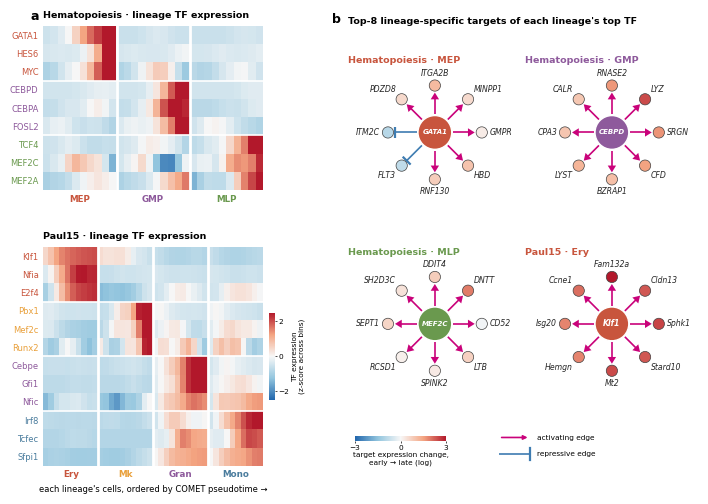

In [11]:
from matplotlib.patches import Circle, FancyArrowPatch, ArrowStyle
EDGE_POS, EDGE_NEG = COMET_C, "#3E7CB1"                                     # COMET pink / benchmark blue
EXPR_DIV = LinearSegmentedColormap.from_list("expr", ["#2166AC", "#92C5DE", "#F7F7F7", "#F4A582", "#B2182B"])
NAME_DS = {"hema": "Hematopoiesis", "paul15": "Paul15"}

def draw_edge(ax, p0, p1, lw, col, activating):
    """shaft + a filled head (activating) or a flat bar (repressive); head size grows only gently with width"""
    u = (p1 - p0) / np.linalg.norm(p1 - p0); v = np.array([-u[1], u[0]])
    hl, hw = 0.13 + 0.012 * lw, 0.075 + 0.012 * lw                          # head length / half-width (data units)
    if activating:
        ax.plot(*np.c_[p0, p1 - u * hl * 0.9], color=col, lw=lw, solid_capstyle="butt", zorder=1)
        ax.add_patch(plt.Polygon([p1, p1 - u * hl + v * hw, p1 - u * hl - v * hw], closed=True, fc=col, ec="none", zorder=1))
    else:
        ax.plot(*np.c_[p0, p1], color=col, lw=lw, solid_capstyle="butt", zorder=1)
        ax.plot(*np.c_[p1 + v * (hw + 0.03), p1 - v * (hw + 0.03)], color=col, lw=max(lw, 1.0) + 0.4,
                solid_capstyle="butt", zorder=1)

def network(ax, ds, L, tf, early, late, smax, enorm, ylim=1.42):
    e = EDGES[(EDGES.dataset == ds) & (EDGES.lineage == L) & (EDGES.tf == tf)].head(K_TGT).reset_index(drop=True)
    n = len(e); ang = np.pi / 2 - 2 * np.pi * np.arange(n) / n; R0, rT, rG = 1.0, 0.36, 0.12
    for i, r in e.iterrows():
        u = np.array([np.cos(ang[i]), np.sin(ang[i])]); lw = 1.2                       # uniform edge width
        draw_edge(ax, u * (rT + 0.03), u * (R0 - rG - 0.03), lw, EDGE_POS if r.edge_mean > 0 else EDGE_NEG, r.edge_mean > 0)
        ax.add_patch(Circle(u * R0, rG, fc=EXPR_DIV(enorm(r.target_expr_change)), ec="0.25", lw=0.5, zorder=2))
        ha = "left" if u[0] > 0.2 else ("right" if u[0] < -0.2 else "center")
        va = "bottom" if u[1] > 0.2 else ("top" if u[1] < -0.2 else "center")
        ax.text(*(u * (R0 + rG + 0.05)), r.target, ha=ha, va=va, fontsize=5.6, fontstyle="italic", color="0.15")
    ax.add_patch(Circle((0, 0), rT, fc=LIN_C[L], ec="white", lw=1.0, zorder=3))
    ax.text(0, 0, tf, ha="center", va="center", fontsize=5.6 if len(tf) <= 4 else 5.0, fontweight="bold",
            fontstyle="italic", color="white", zorder=4)
    ax.set_xlim(-1.85, 1.85); ax.set_ylim(-ylim, ylim); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{NAME_DS[ds]} · {L}", loc="left", fontsize=6.8, color=LIN_C[L], pad=2)

smax = max(EDGES[(EDGES.dataset == ds) & (EDGES.lineage == L) & (EDGES.tf == tf)].head(K_TGT).S.max() for ds, L, tf, *_ in NETS)
enorm = TwoSlopeNorm(0, -3, 3)
NR_NET = int(np.ceil(len(NETS) / 2))

def lineage_heatmaps(fig, gl, letter):
    """lineage TF expression (z-scored across bins), hema above paul15, colour bar under the lower one"""
    for r_, ds in enumerate(["hema", "paul15"]):
        sel = [tf for _, tf, _, _ in TOP[ds]]; d = D[ds]
        P = lineage_profile_matrix(d, d["XT"], sel, scale=None)
        P = np.clip((P - P.mean(1, keepdims=True)) / (P.std(1, keepdims=True) + 1e-12), -2.5, 2.5)   # z-score across bins
        ax = fig.add_subplot(gl[r_]); im = heat_blocks(ax, P, ds, EXPR_DIV, vmin=-2.5, vmax=2.5, star=False)
        ax.set_title(NAME_DS[ds] + " · lineage TF expression", loc="left", fontsize=6.8)
        if r_ == 0: panel(ax, letter)
    ax.set_xlabel("each lineage's cells, ordered by COMET pseudotime →", fontsize=6)
    cax = ax.inset_axes([1.03, 0.30, 0.025, 0.40])
    cb = fig.colorbar(im, cax=cax, orientation="vertical", ticks=[-2, 0, 2])
    cb.set_label("TF expression\n(z-score across bins)", fontsize=5.3, labelpad=2)
    cb.ax.tick_params(labelsize=5.3, length=1.5, pad=1); cb.outline.set_visible(False)

def network_block(fig, cell, letter, hspace=0.14, ylim=1.42, header=0.02):
    """header + 2-column grid of lineage networks + legend row, all inside `cell`"""
    g = cell.subgridspec(NR_NET + 2, 2, height_ratios=[header] + [1.0] * NR_NET + [0.22], wspace=0.02, hspace=hspace)
    hd = fig.add_subplot(g[0, :]); hd.axis("off"); panel(hd, letter)
    hd.set_title(f"Top-{K_TGT} lineage-specific targets of each lineage's top TF",
                 loc="left", fontsize=6.8, pad=0)
    for i, (ds, L, tf, early, late) in enumerate(NETS):
        network(fig.add_subplot(g[1 + i // 2, i % 2]), ds, L, tf, early, late, smax, enorm, ylim)
    leg = fig.add_subplot(g[-1, :]); leg.axis("off"); leg.set_xlim(0, 1); leg.set_ylim(0, 1)
    cax = leg.inset_axes([0.02, 0.62, 0.26, 0.14])
    c2 = fig.colorbar(plt.cm.ScalarMappable(norm=enorm, cmap=EXPR_DIV), cax=cax, orientation="horizontal", ticks=[-3, 0, 3])
    c2.set_label("target expression change,\nearly → late (log)", fontsize=5.3, labelpad=1)
    c2.ax.tick_params(labelsize=5.3, length=1.5, pad=1); c2.outline.set_visible(False)
    leg.annotate("", (0.52, 0.72), (0.43, 0.72), arrowprops=dict(arrowstyle="-|>", color=EDGE_POS, lw=1.2, mutation_scale=6))
    leg.text(0.54, 0.72, "activating edge", va="center", fontsize=5.3)
    leg.plot([0.43, 0.52], [0.30, 0.30], color=EDGE_NEG, lw=1.2, solid_capstyle="butt"); leg.plot([0.52, 0.52], [0.14, 0.46], color=EDGE_NEG, lw=1.6)
    leg.text(0.54, 0.30, "repressive edge", va="center", fontsize=5.3)

fig = plt.figure(figsize=(7.2, 1.15 + 1.95 * NR_NET))
outer = fig.add_gridspec(1, 2, width_ratios=[1.25, 2.0], wspace=0.30, left=0.08, right=0.99, top=0.95, bottom=0.08)
lineage_heatmaps(fig, outer[0].subgridspec(2, 1, height_ratios=[3, 4], hspace=0.30), "a")
network_block(fig, outer[1], "b")
fig.savefig(f"{FIG}/fig1a_lineage_tfs_branch_edges.pdf"); fig.savefig(f"{FIG}/fig1a_lineage_tfs_branch_edges.png"); plt.show()

## 5 · AML: GRN rewiring at the stage transitions (Fig. 2a)

**Setup.**
- The AML blast trajectory is linear. The `ery` cells are a small side branch, so they are excluded (sensitivity check below).
- Cells are ordered by **COMET pseudotime** and split into **40 equal-cell bins**.

**GRN rewiring per step.**
- $\Delta A_b = \sum_k (\bar w_{b+1,k} - \bar w_{b,k})\,A^{(k)}$, where $\bar w_b$ is the bin's mean module weight.
- $\|\Delta A_b\|_F$ is computed exactly from the module Gram matrix.
- Bands: 95% bootstrap over cells within bins (200 resamples).

**Stage boundaries** (labels; annotation only). For consecutive stages $a\to b$, the boundary step is where $b$'s fraction first overtakes $a$'s.

**Focus transitions.** Two boundaries are analysed in detail: **immature → blast0** and **blast2 → blast3**.
- Each focus step is the largest rewiring step within ±1 step of its boundary.
- The other two boundaries are marked but not analysed.

**Why two.** On this GRN, which single step is largest depends on the bin count:
- blast2 → blast3 is the largest in most settings;
- immature → blast0 is among the top peaks in most settings.

The tables below give each boundary's rank, its bootstrap stability and the bin-count sensitivity.

In [12]:
A = D["aml89"]; NB = 40
def aml_bins(keep, nb):
    idx = np.where(keep)[0]; o = idx[np.argsort(A["pt"][idx], kind="stable")]; return np.array_split(o, nb)
Gram = np.einsum("kgt,lgt->kl", A["A_dict"], A["A_dict"])
def rewiring(bins):
    W = np.array([A["mix"][b].mean(0) for b in bins]); dW = np.diff(W, axis=0)
    return np.sqrt(np.einsum("bk,kl,bl->b", dW, Gram, dW))
def composition(bins):
    return pd.DataFrame([pd.Series(A["ct"][b]).value_counts(normalize=True) for b in bins]).reindex(columns=AML_STAGES).fillna(0)

STAGE_PAIRS = list(zip(AML_STAGES, AML_STAGES[1:]))
SHORT_ST = {"immature": "imm", "blast0": "b0", "blast1": "b1", "blast2": "b2", "blast3": "b3"}
def stage_steps(comp):
    """boundary step of each consecutive stage pair a -> b: the bin where b's fraction first exceeds a's (after a's
    peak), minus one"""
    out = {}
    for a, b in STAGE_PAIRS:
        fa, fb = comp[a].values, comp[b].values; s0 = int(np.argmax(fa))
        out[(a, b)] = s0 + int(np.argmax(fb[s0:] > fa[s0:])) - 1
    return out
def local_peak(r, s): lo_ = max(s - 1, 0); return lo_ + int(np.argmax(r[lo_:s + 2]))
def rank_of(r, s): return int((r > r[s]).sum()) + 1

BINS = aml_bins(A["ct"] != "ery", NB)
REW = rewiring(BINS); rng = np.random.default_rng(SEED)
REW_BOOT = np.array([rewiring([rng.choice(b, len(b)) for b in BINS]) for _ in range(N_BOOT)])
COMP = composition(BINS); BSTEP = stage_steps(COMP)
FOCUS = {k: local_peak(REW, BSTEP[k]) for k in [("immature", "blast0"), ("blast2", "blast3")]}
FLAB = {k: f"{k[0]} → {k[1]}" for k in FOCUS}
BURST, BURST2 = FOCUS[("immature", "blast0")], FOCUS[("blast2", "blast3")]
WIN = sorted({w for s in FOCUS.values() for w in (s - 1, s, s + 1) if 0 <= w < len(REW)})
BTAB = pd.DataFrame([dict(transition=f"{a} → {b}", boundary_step=BSTEP[(a, b)], local_peak_step=local_peak(REW, BSTEP[(a, b)]),
                          rewiring=REW[local_peak(REW, BSTEP[(a, b)])],
                          x_median_step=REW[local_peak(REW, BSTEP[(a, b)])] / np.median(REW),
                          rank_of_39=rank_of(REW, local_peak(REW, BSTEP[(a, b)])),
                          boot_top3=np.mean([rank_of(rb, local_peak(rb, BSTEP[(a, b)])) <= 3 for rb in REW_BOOT]),
                          focus=(a, b) in FOCUS) for a, b in STAGE_PAIRS])
BTAB.to_csv(f"{TAB}/aml_rewiring_at_boundaries.csv", index=False)
print("largest step overall:", int(np.argmax(REW)), "| focus steps:", {FLAB[k]: s for k, s in FOCUS.items()})
BTAB.round(2)

largest step overall: 13 | focus steps: {'immature → blast0': 2, 'blast2 → blast3': 23}


,transition,boundary_step,local_peak_step,rewiring,x_median_step,rank_of_39,boot_top3,focus
0,immature → blast0,2,2,3.39,5.35,3,1.00,True
1,blast0 → blast1,11,12,0.82,1.29,17,0.00,False
2,blast1 → blast2,13,13,3.76,5.94,1,1.00,False
3,blast2 → blast3,22,23,3.49,5.51,2,0.93,True


In [13]:
# sensitivity: rank of each boundary's local rewiring peak, by bin count x ery kept/excluded
sens = []
for keep_name, keep in [("ery excluded", A["ct"] != "ery"), ("ery kept", np.ones(len(A["pt"]), bool))]:
    for nb in (20, 30, 40, 50, 60):
        bs = aml_bins(keep, nb); r = rewiring(bs); bst = stage_steps(composition(bs))
        sens.append(dict(cells=keep_name, bins=nb, largest_step_at=f"{(int(np.argmax(r)) + 1) / nb:.2f}",
                         **{f"rank {SHORT_ST[a]}→{SHORT_ST[b]}": rank_of(r, local_peak(r, bst[(a, b)])) for a, b in STAGE_PAIRS}))
SENS = pd.DataFrame(sens); SENS.to_csv(f"{TAB}/aml_burst_sensitivity.csv", index=False); SENS

,cells,bins,largest_step_at,rank imm→b0,rank b0→b1,rank b1→b2,rank b2→b3
0,ery excluded,20,0.60,3,2,2,1
1,ery excluded,30,0.60,2,3,3,1
2,ery excluded,40,0.35,3,17,1,2
3,ery excluded,50,0.08,1,30,3,2
4,ery excluded,60,0.08,1,25,2,3
5,ery kept,20,0.60,3,2,2,1
6,ery kept,30,0.07,1,3,3,2
7,ery kept,40,0.60,2,3,3,1
8,ery kept,50,0.36,2,20,1,3
9,ery kept,60,0.08,1,41,2,3


## 6 · AML: TF-wide transcriptional switches and the HOX/MEIS programme at the focus transitions (Fig. 2b–d)

**Rate of change.** For each expressed TF: bin-mean expression, Gaussian-smoothed (σ = 1 bin), differenced between adjacent bins, and divided by the TF's s.d. This gives a standardised rate per step on the same 39 steps as the rewiring.

**Tests.**
- **(b) TF-wide switch.** Do TFs' fastest-change steps pile up in the focus windows (each focus step ±1) more than a uniform spread would? One-sided binomial test, for both windows together and for each separately.
- **(c) HOX/MEIS programme.** The rate curves of HOXA9, MEIS1, PBX3 and HOXA10, chosen in the config.
- **(d) Associated TFs.** At each focus step, the 5 expressed TFs with the largest positive and the 5 with the largest negative rate, unsupervised. A TF already used at an earlier transition is skipped. Full rankings: `tables_final/aml_tfs_at_<transition>.csv`.

In [14]:
ok = A["expressed"]; tfl = list(A["tfs"])
XB = gaussian_filter1d(np.array([A["XT"][b].mean(0) for b in BINS]), 1.0, axis=0)
RATE = np.diff(XB, axis=0) / (A["XT"].std(0) + 1e-8)                   # (39 steps, T) standardised rate
peak_step = np.argmax(np.abs(RATE), axis=0)
in_win = np.isin(peak_step, WIN) & ok
BT = binomtest(int(in_win.sum()), int(ok.sum()), len(WIN) / RATE.shape[0], alternative="greater")
print(f"both windows: {in_win.sum()}/{ok.sum()} expressed TFs change fastest there "
      f"(expected {ok.sum() * len(WIN) / RATE.shape[0]:.1f}); binomial p = {BT.pvalue:.1e}")
for k, s in FOCUS.items():
    w = [x_ for x_ in (s - 1, s, s + 1) if 0 <= x_ < RATE.shape[0]]; n_ = int((np.isin(peak_step, w) & ok).sum())
    print(f"  {FLAB[k]} window {w}: {n_} TFs (expected {ok.sum() * len(w) / RATE.shape[0]:.1f}); "
          f"p = {binomtest(n_, int(ok.sum()), len(w) / RATE.shape[0], alternative='greater').pvalue:.1e}")

N_ROW = 5; TFS_AT, GROUPS, used = {}, [], set()
for k, s in FOCUS.items():
    t_ = pd.DataFrame(dict(tf=A["tfs"], expressed=ok, rate=RATE[s], fastest_change_step=peak_step)).sort_values("rate", ascending=False)
    t_.to_csv(f"{TAB}/aml_tfs_at_{k[0]}_{k[1]}.csv", index=False); TFS_AT[k] = t_
    e_ = t_[t_.expressed].tf.values
    up = [g for g in e_ if g not in used][:N_ROW]; used |= set(up)
    dn = [g for g in e_[::-1] if g not in used][:N_ROW]; used |= set(dn)
    GROUPS += [(k, "up", up), (k, "down", dn)]
    print(f"{FLAB[k]} (step {s}): up {up}; down {dn}")
EXTRA = [g for g in AML_PROGRAM if g not in used]
e = TFS_AT[("immature", "blast0")]; e = e[e.expressed]
print("HOX/MEIS fastest-change step:", {g: int(peak_step[tfl.index(g)]) for g in AML_PROGRAM},
      "| focus steps:", {FLAB[k]: s for k, s in FOCUS.items()})

both windows: 123/293 expressed TFs change fastest there (expected 45.1); binomial p = 1.1e-27
  immature → blast0 window [1, 2, 3]: 101 TFs (expected 22.5); p = 3.5e-39
  blast2 → blast3 window [22, 23, 24]: 22 TFs (expected 22.5); p = 5.8e-01
immature → blast0 (step 2): up ['PBX3', 'IKZF1', 'CEBPA', 'NFE2', 'HOXA9']; down ['ID1', 'MAFF', 'NR4A1', 'ID2', 'ARID5A']
blast2 → blast3 (step 23): up ['SPI1', 'KLF3', 'MAFB', 'POU2F2', 'HIF1A']; down ['ENO1', 'HOXB4', 'GFI1', 'HMGN3', 'RUNX2']
HOX/MEIS fastest-change step: {'HOXA9': 2, 'MEIS1': 1, 'PBX3': 2, 'HOXA10': 13} | focus steps: {'immature → blast0': 2, 'blast2 → blast3': 23}


In [15]:
# shared drawing helpers for Fig. 2, 2a and 2b (x axis: bin j spans [j, j+1]; step b sits at x = b + 1)
UPC, DNC = "#5A0034", "#4A7C9D"
def mark_boundaries(ax, label=False, focus_color="k"):
    for k, s in BSTEP.items():
        if k in FOCUS: ax.axvline(FOCUS[k] + 1, color=focus_color, lw=0.8, ls=(0, (2, 1.5)), zorder=0)
        else: ax.axvline(s + 1, color="0.6", lw=0.6, ls=(0, (1, 1.5)), zorder=0)
    if label:
        xs = [FOCUS.get(k, s) + 1 for k, s in BSTEP.items()]
        for j, (k, x_) in enumerate(zip(BSTEP, xs)):
            close_prev = j > 0 and x_ - xs[j - 1] < 4; close_next = j < len(xs) - 1 and xs[j + 1] - x_ < 4
            ha = "left" if close_prev else ("right" if close_next else "center")
            ax.text(x_ + (0.3 if ha == "left" else -0.3 if ha == "right" else 0), 1.02, f"{SHORT_ST[k[0]]}→{SHORT_ST[k[1]]}",
                    transform=ax.get_xaxis_transform(), ha=ha, va="bottom", fontsize=5.0,
                    color="k" if k in FOCUS else "0.5", fontweight="bold" if k in FOCUS else "normal")

def rewiring_panel(ax):
    xb = np.arange(len(REW)) + 1.0; lo, hi = np.percentile(REW_BOOT, [2.5, 97.5], axis=0)
    ax.fill_between(xb, lo, hi, color=COMET_C, alpha=0.25, lw=0); ax.plot(xb, REW, color=COMET_C, lw=1.2)
    mark_boundaries(ax, label=True)
    ax.set_ylabel("GRN rewiring\n‖ΔA‖ per step"); ax.set_xlim(0, NB); ax.set_xticks([])
    ax.set_title("COMET's GRN rewires at the AML stage transitions", loc="left", pad=12)

def stage_strip(axs, legend_y=-0.05):
    bottom = np.zeros(NB)
    for st in AML_STAGES:
        axs.bar(np.arange(NB) + 0.5, COMP[st].values, bottom=bottom, width=1.0, color=STAGE_C[st], lw=0, label=st); bottom += COMP[st].values
    for s in FOCUS.values(): axs.axvline(s + 1, color="white", lw=0.8, ls=(0, (2, 1.5)))
    axs.set_ylim(0, 1); axs.set_yticks([]); [axs.spines[k].set_visible(False) for k in ("left", "bottom")]
    axs.tick_params(axis="x", length=0, labelbottom=False)
    axs.set_ylabel("stage", rotation=0, ha="right", va="center", fontsize=5.8)
    axs.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, legend_y), handlelength=0.8, columnspacing=0.9,
               fontsize=5.3, borderaxespad=0.1)

ZCMAP = LinearSegmentedColormap.from_list("zexpr", ["#2166AC", "#92C5DE", "#F7F7F7", "#F4A582", "#B2182B"])
def tf_heat(ax_, rows, z=False):
    H = XB[:, [tfl.index(g) for g in rows]].T
    if z: H = np.clip((H - H.mean(1, keepdims=True)) / (H.std(1, keepdims=True) + 1e-12), -2.5, 2.5); kw = dict(cmap=ZCMAP, vmin=-2.5, vmax=2.5)
    else: H = H / (H.max(1, keepdims=True) + 1e-12); kw = dict(cmap=HEAT, vmin=0, vmax=1)
    im = ax_.imshow(H, aspect="auto", interpolation="nearest", extent=(0, NB, len(rows), 0), **kw)
    for s in FOCUS.values(): ax_.axvline(s + 1, color="k", lw=0.8, ls=(0, (2, 1.5)))
    ax_.set_yticks(np.arange(len(rows)) + 0.5, rows, fontsize=5.6)
    ax_.tick_params(length=0); [s_.set_visible(False) for s_ in ax_.spines.values()]
    return im

def grouped_heat(axh, z=False, plain=False):
    """plain=True: TF names in black, regular weight, and a thin bracket beside each group label"""
    rows = [g for *_, gs_ in GROUPS for g in gs_]; im = tf_heat(axh, rows, z)
    pos = 0
    for i, (k, d_, gs_) in enumerate(GROUPS):
        col = UPC if d_ == "up" else DNC
        if not plain:
            for t in axh.get_yticklabels()[pos:pos + len(gs_)]: t.set_color(col); \
                t.set_fontweight("bold" if t.get_text() in AML_PROGRAM else "normal")
        y0, y1 = 1 - (pos + 0.15) / len(rows), 1 - (pos + len(gs_) - 0.15) / len(rows)
        if plain:
            axh.plot([1.006, 1.012, 1.012, 1.006], [y0, y0, y1, y1], transform=axh.transAxes, color="0.35", lw=0.6,
                     clip_on=False, solid_capstyle="butt")
        axh.text(1.022 if plain else 1.01, (y0 + y1) / 2, f"{d_} at\n{SHORT_ST[k[0]]}→{SHORT_ST[k[1]]}",
                 transform=axh.transAxes, color=col, fontweight="bold", fontsize=5.0, va="center")
        pos += len(gs_)
        if pos < len(rows): axh.axhline(pos, color="white", lw=2.2 if i % 2 else 0.9)
    return im

def extra_heat(axe, z=False, plain=False):
    tf_heat(axe, EXTRA, z)
    if plain: return
    for t in axe.get_yticklabels(): t.set_color(UPC); t.set_fontweight("bold")
    axe.text(1.01, 0.5, "HOX/\nMEIS", transform=axe.transAxes, color=UPC, fontweight="bold", fontsize=5.0, va="center")

## Figure 2 · AML: COMET's GRN rewires at the stage transitions, alongside TF-wide switches and the HOX/MEIS programme

The x-axis throughout is the 40 equal-cell bins, ordered by **COMET pseudotime**.
- **Black dashed lines:** the two focus transitions (immature → blast0, blast2 → blast3).
- **Grey dotted lines:** the other stage boundaries.

Panels:
- **(a)** GRN rewiring per step (95% bootstrap band), above the stage composition of each bin.
- **(b)** For each step, how many TFs have their fastest expression change there; the dashed line is the uniform expectation.
- **(c)** Standardised expression rate of HOXA9, MEIS1, PBX3 and HOXA10.
- **(d)** At each focus transition, the 5 TFs rising fastest and the 5 falling fastest (unsupervised), shown as expression along the trajectory, each row scaled to its maximum.

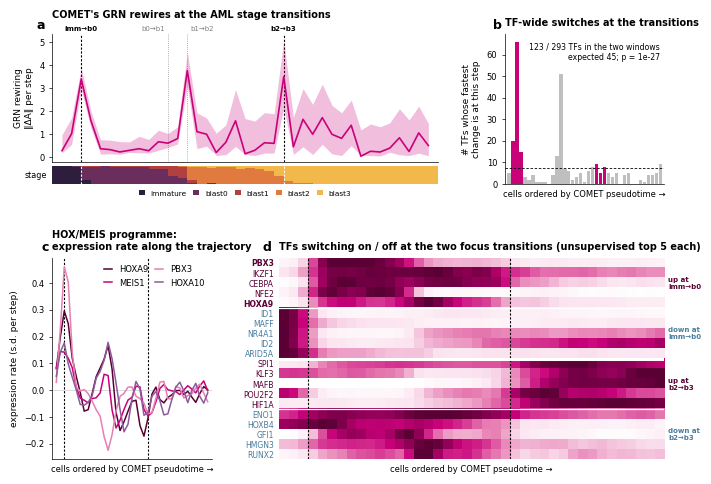

In [16]:
xb = np.arange(len(REW)) + 1.0
fig = plt.figure(figsize=(7.2, 5.0))
gs = fig.add_gridspec(2, 3, width_ratios=[1.0, 1.0, 1.0], height_ratios=[1.0, 1.35], hspace=0.42, wspace=0.42,
                      left=0.08, right=0.93, top=0.92, bottom=0.07)
ga = gs[0, :2].subgridspec(2, 1, height_ratios=[4.0, 0.55], hspace=0.06)
ax = fig.add_subplot(ga[0]); panel(ax, "a"); rewiring_panel(ax)
axs = fig.add_subplot(ga[1], sharex=ax); stage_strip(axs, legend_y=-0.15)

ax = fig.add_subplot(gs[0, 2]); panel(ax, "b")
cnt = np.bincount(peak_step[ok], minlength=RATE.shape[0])
ax.bar(xb, cnt, width=0.9, color=[COMET_C if i in WIN else "0.75" for i in range(len(cnt))], lw=0)
ax.axhline(ok.sum() / RATE.shape[0], color="k", lw=0.6, ls=(0, (3, 2)))
ax.text(0.97, 0.95, f"{in_win.sum()} / {ok.sum()} TFs in the two windows\nexpected {ok.sum()*len(WIN)/RATE.shape[0]:.0f}; p = {BT.pvalue:.0e}",
        transform=ax.transAxes, ha="right", va="top", fontsize=5.6)
ax.set_xlim(0, NB); ax.set_ylabel("# TFs whose fastest\nchange is at this step"); ax.set_xticks([])
ax.set_xlabel("cells ordered by COMET pseudotime →", fontsize=6)
ax.set_title("TF-wide switches at the transitions", loc="left")

ax = fig.add_subplot(gs[1, 0]); panel(ax, "c")
for s in FOCUS.values(): ax.axvline(s + 1, color="k", lw=0.8, ls=(0, (2, 1.5)))
ax.axhline(0, color="0.8", lw=0.5)
pc_ = {"HOXA9": "#5A0034", "MEIS1": "#c9027a", "PBX3": "#E77FB3", "HOXA10": "#8E5A9C"}
for g in AML_PROGRAM: ax.plot(xb, RATE[:, tfl.index(g)], color=pc_[g], lw=1.1, label=g)
ax.set_xlim(0, NB); ax.set_ylabel("expression rate (s.d. per step)"); ax.set_xticks([])
ax.legend(ncol=2, loc="upper right", handlelength=1.0, columnspacing=0.8)
ax.set_title("HOX/MEIS programme:\nexpression rate along the trajectory", loc="left")
ax.set_xlabel("cells ordered by COMET pseudotime →", fontsize=6)

ax = fig.add_subplot(gs[1, 1:]); panel(ax, "d"); grouped_heat(ax)
ax.set_xticks([]); ax.set_xlabel("cells ordered by COMET pseudotime →", fontsize=6)
ax.set_title("TFs switching on / off at the two focus transitions (unsupervised top 5 each)", loc="left")
fig.savefig(f"{FIG}/fig2_aml_burst.pdf"); fig.savefig(f"{FIG}/fig2_aml_burst.png"); plt.show()

## 7 · Which TFs change expression most at each focus transition? (top 12 each way)

The standardised expression rate at each focus step (expressed TFs only), 12 per direction. Also printed: where the HOX/MEIS programme ranks at immature → blast0.

In [17]:
TOP12 = pd.concat([pd.concat([t_[t_.expressed].head(12).assign(direction="up"), t_[t_.expressed].tail(12).iloc[::-1].assign(direction="down")]
                              ).assign(transition=FLAB[k]) for k, t_ in TFS_AT.items()])
TOP12 = TOP12[["transition", "direction", "tf", "rate", "fastest_change_step"]].reset_index(drop=True)
TOP12.to_csv(f"{TAB}/aml_burst_tfs_top12.csv", index=False)
RANK_UP = {g: int(np.where(e.tf.values == g)[0][0]) + 1 for g in AML_PROGRAM}
print("rank among", len(e), "expressed TFs at immature → blast0 (1 = largest increase):", RANK_UP)
TOP12

rank among 293 expressed TFs at immature → blast0 (1 = largest increase): {'HOXA9': 5, 'MEIS1': 35, 'PBX3': 1, 'HOXA10': 19}


,transition,direction,tf,rate,fastest_change_step
0,immature → blast0,up,PBX3,0.460451,2
1,immature → blast0,up,IKZF1,0.364661,2
2,immature → blast0,up,CEBPA,0.336641,2
3,immature → blast0,up,NFE2,0.320933,13
4,immature → blast0,up,HOXA9,0.295576,2
5,immature → blast0,up,KLF6,0.264424,2
6,immature → blast0,up,SOX4,0.244313,2
7,immature → blast0,up,SPI1,0.244240,2
8,immature → blast0,up,ATF6B,0.222380,2
9,immature → blast0,up,TFDP1,0.206364,12


## 8 · Which TF regulons agree with COMET's direction at immature → blast0, and do they gain weight there?

Everything here is read from the COMET run (`comet_outputs_post_review/aml89/`); nothing is refitted.

**Windows** (AML blast trajectory, `ery` excluded, the 40 COMET-pseudotime bins of Fig. 2):
- **transition window:** the 3 bins right after the immature → blast0 focus step;
- **preceding bins:** all bins before that step (mostly immature cells).

**A · Directional agreement:** COMET's saved TF activity velocity `grn_activity_velocity.npy`, $a_{it}$. In the tilt, each cell's displacement is regressed on its own signed regulons, and $a_{it}$ is TF $t$'s coefficient.
- $a_{it} > 0$: TF $t$'s signed regulon points *along* the cell's direction of progression, i.e. its programme is switching on.
- $a_{it} < 0$: it points against it, i.e. the programme is switching off.
- Score: mean $a_{it}$ over the window, divided by the TF's s.d. of $a$ over all cells, so TFs are comparable. TFs are ranked by |score|.
- The run's saved explained fraction `grn_explained_fraction.npy` ($R^2_i$) is reported for both windows.
- This is a model-derived agreement, not evidence of biological activation.

**B · Regulatory prominence increasing at the switch.** This uses the GRN's own per-cell weights (saved `A_base`, `A_dict`, `mix_weights`), not TF mRNA:
- the TF-specific log hub score of Fig. 1b, $\log(o_{it}/\bar o_t)$ minus the cell's median over TFs, where $o_{it} = \sum_g |A_{i,gt}|$;
- score: its mean in the window minus its mean in the preceding bins;
- it can only change through the 4 module weights, so it measures module-level re-weighting of the TF's regulon.

**Controls.**
- Grey dots in (A): the same TF's score in the preceding bins.
- Grey band in (B): the 5–95% range over all expressed TFs.
- Error bars: 95% bootstrap over cells.

In [18]:
AG = np.load(f"{RF}/aml89/grn_activity_velocity.npy")                        # COMET's TF activity velocity (N, T)
R2G = np.load(f"{RF}/aml89/grn_explained_fraction.npy")                       # COMET's GRN-explained fraction (N,)
assert AG.shape == (len(A["pt"]), len(A["tfs"])) and R2G.shape == (len(A["pt"]),)
A_SD = AG.std(0) + 1e-12

PRE = np.concatenate(BINS[:BURST + 1]); POST = np.concatenate(BINS[BURST + 1:BURST + 4])
print(f"preceding bins 0-{BURST}: {len(PRE)} cells; transition window bins {BURST+1}-{BURST+3}: {len(POST)} cells")
print(f"COMET's GRN-explained fraction R²: window {R2G[POST].mean():.3f}, preceding bins {R2G[PRE].mean():.3f}")

O = weighted_outdegree(A); has = O.mean(0) > 0                             # TFs without prior edges have no hub score
LO = np.full_like(O, np.nan); LO[:, has] = np.log(O[:, has] / O[:, has].mean(0))
LO = LO - np.median(LO[:, ok & has], axis=1, keepdims=True)              # TF-specific log hub score (as Fig. 1b)

rng = np.random.default_rng(SEED); bA, bB = [], []
for _ in range(N_BOOT):
    p, q = rng.choice(PRE, len(PRE)), rng.choice(POST, len(POST))
    bA.append(AG[q].mean(0) / A_SD); bB.append(LO[q].mean(0) - LO[p].mean(0))
bA, bB = np.array(bA), np.array(bB)
EXPL = pd.DataFrame(dict(tf=A["tfs"], expressed=ok & (AG != 0).any(0),
                         activity_window=AG[POST].mean(0) / A_SD, act_lo=np.percentile(bA, 2.5, 0),
                         act_hi=np.percentile(bA, 97.5, 0), activity_preceding=AG[PRE].mean(0) / A_SD,
                         hub_gain=LO[POST].mean(0) - LO[PRE].mean(0), hub_lo=np.percentile(bB, 2.5, 0),
                         hub_hi=np.percentile(bB, 97.5, 0)))
EXPL = EXPL[EXPL.expressed].drop(columns="expressed")
EXPL = EXPL.reindex(EXPL.activity_window.abs().sort_values(ascending=False).index)
EXPL["hub_gain_pct_rank"] = EXPL.hub_gain.rank(pct=True)
EXPL.to_csv(f"{TAB}/aml_burst_explaining_tfs.csv", index=False)
HUB_BAND = np.nanpercentile(EXPL.hub_gain, [5, 95])
print("hub-gain 5–95% over expressed TFs:", HUB_BAND.round(3))
EXPL.head(20).round(3)

preceding bins 0-2: 372 cells; transition window bins 3-5: 372 cells
COMET's GRN-explained fraction R²: window 0.066, preceding bins 0.080


hub-gain 5–95% over expressed TFs: [-0.141  0.174]


,tf,activity_window,act_lo,act_hi,activity_preceding,hub_gain,hub_lo,hub_hi,hub_gain_pct_rank
235,KLF6,1.153,1.062,1.258,0.510,0.174,0.127,0.216,0.952
415,TCF7L2,-0.937,-1.021,-0.834,-0.303,0.016,0.009,0.024,0.584
26,GATA2,-0.918,-1.030,-0.804,-0.124,0.103,0.095,0.110,0.828
80,HOXB6,-0.913,-1.009,-0.819,-0.207,-0.055,-0.062,-0.046,0.263
783,TOPORS,-0.908,-1.012,-0.812,0.395,-0.036,-0.041,-0.031,0.330
76,HOXB4,-0.905,-1.008,-0.794,-0.917,0.082,0.075,0.089,0.785
396,NR1H2,0.859,0.765,0.954,0.300,-0.032,-0.035,-0.030,0.340
706,ZNF136,-0.858,-0.957,-0.745,0.230,0.003,-0.002,0.006,0.517
259,PLAGL1,-0.856,-0.958,-0.763,0.034,-0.014,-0.017,-0.012,0.416
707,ZNF134,-0.822,-0.900,-0.745,0.294,0.125,0.120,0.129,0.871


## Figure 2a · Expression dynamics and regulatory programmes at the AML stage transitions

One x-axis for (a) and (b): the 40 equal-cell bins along **COMET pseudotime**.
- **Black dashed lines:** the two focus transitions (immature → blast0, blast2 → blast3).
- **Grey dotted lines:** the other stage boundaries.

Panels:
- **(a)** GRN rewiring per step (95% bootstrap band), above the stage composition of each bin.
- **(b)** TFs with the largest expression increases and decreases at each focus transition (unsupervised top 5 each way, §6), plus the HOX/MEIS programme. Rows are bin-mean expression, smoothed (σ = 1 bin) and scaled to each row's maximum.
- **(c)** At immature → blast0: the TFs whose regulons agree most with COMET's direction (§8 A), i.e. COMET's TF activity velocity in s.d. units. Pink = along the progression (programme on); blue = against it (programme off). Grey dots: the same TF in the preceding bins.
- **(d)** The same TFs' change in regulatory prominence in COMET's GRN from the preceding bins into the window (§8 B: TF-specific log hub score). Grey band: 5–95% over all expressed TFs.

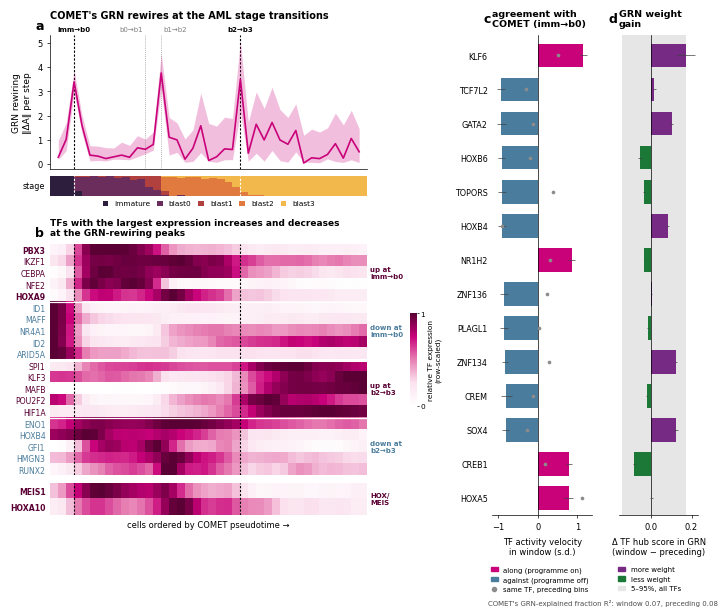

In [19]:
def burst_column(fig, gl, z=False, legend_y=-0.05, cbar_dx=0.06, letters=("a", "b"), plain=False):
    """(a) rewiring + stage strip, (b) grouped TF heatmap + HOX/MEIS rows, sharing one x axis; returns the heatmap axes"""
    ax = fig.add_subplot(gl[0]); panel(ax, letters[0]); rewiring_panel(ax)
    axs = fig.add_subplot(gl[1], sharex=ax); stage_strip(axs, legend_y)
    axh = fig.add_subplot(gl[3], sharex=ax); panel(axh, letters[1]); im = grouped_heat(axh, z, plain)
    axh.tick_params(axis="x", labelbottom=False)
    axh.set_title("TFs with the largest expression increases and decreases" + (" " if plain else "\n") + "at the GRN-rewiring peaks",
                  loc="left", fontsize=6.5)
    last = axh
    if EXTRA:
        last = fig.add_subplot(gl[4], sharex=ax); extra_heat(last, z, plain)
    last.tick_params(axis="x", labelbottom=False)
    last.set_xlabel("cells ordered by COMET pseudotime →", fontsize=6)
    pb = axh.get_position()
    cax = fig.add_axes([pb.x1 + cbar_dx, pb.y0 + 0.3 * pb.height, 0.009, 0.4 * pb.height])
    cb = fig.colorbar(im, cax=cax, orientation="vertical", ticks=[-2, 0, 2] if z else [0, 1])
    cb.ax.tick_params(labelsize=5.3, length=1.5, pad=1); cb.outline.set_visible(False)
    cb.set_label("expression (z-score\nacross bins)" if z else "relative TF expression\n(row-scaled)", fontsize=5.3, labelpad=2)
    return axh

N_BAR = 14
n_rows = sum(len(g_) for *_, g_ in GROUPS)
HROWS = [2.2, 0.32, 0.55, 0.19 * n_rows, 0.19 * max(len(EXTRA), 1) + 0.15]
fig = plt.figure(figsize=(7.2, 6.0))
outer = fig.add_gridspec(1, 2, width_ratios=[2.0, 1.3], wspace=0.48, left=0.08, right=0.98, top=0.92, bottom=0.12)
gl = outer[0].subgridspec(5, 1, height_ratios=HROWS, hspace=0.08)
burst_column(fig, gl, z=False)

gr = outer[1].subgridspec(1, 2, width_ratios=[1.0, 0.8], wspace=0.30)
cs = EXPL.head(N_BAR).reset_index(drop=True); yy = np.arange(len(cs))
axc = fig.add_subplot(gr[0]); panel(axc, "c")
axc.barh(yy, cs.activity_window, color=np.where(cs.activity_window > 0, COMET_C, "#4A7C9D"), height=0.7, lw=0)
axc.errorbar(cs.activity_window, yy, xerr=[cs.activity_window - cs.act_lo, cs.act_hi - cs.activity_window], fmt="none",
             ecolor="0.25", elinewidth=0.5, capsize=0)
axc.scatter(cs.activity_preceding, yy, s=7, color="0.55", zorder=3, lw=0)
axc.axvline(0, color="k", lw=0.5)
axc.set_yticks(yy, cs.tf, fontsize=5.8)
axc.set_ylim(len(cs) - 0.5, -0.6); axc.tick_params(axis="y", length=0); axc.spines["left"].set_visible(False)
axc.set_xlabel("TF activity velocity\nin window (s.d.)", fontsize=6)
axc.set_title("agreement with\nCOMET (imm→b0)", loc="left", fontsize=6.8)

axd = fig.add_subplot(gr[1], sharey=axc); panel(axd, "d")
axd.axvspan(*HUB_BAND, color="0.9", lw=0); axd.axvline(0, color="k", lw=0.5)
axd.barh(yy, cs.hub_gain, color=np.where(cs.hub_gain > 0, "#762A83", "#1B7837"), height=0.7, lw=0)
axd.errorbar(cs.hub_gain, yy, xerr=[cs.hub_gain - cs.hub_lo, cs.hub_hi - cs.hub_gain], fmt="none",
             ecolor="0.25", elinewidth=0.5, capsize=0)
axd.tick_params(axis="y", labelleft=False, length=0); axd.spines["left"].set_visible(False)
axd.set_xlabel("Δ TF hub score in GRN\n(window − preceding)", fontsize=6)
axd.set_title("GRN weight\ngain", loc="left", fontsize=6.8)

axc.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COMET_C, label="along (programme on)"),
                    plt.Rectangle((0, 0), 1, 1, color="#4A7C9D", label="against (programme off)"),
                    Line2D([], [], ls="", marker="o", ms=3, color="0.55", label="same TF, preceding bins")],
           loc="upper left", bbox_to_anchor=(-0.05, -0.10), fontsize=5.0, handlelength=1.0, borderaxespad=0.1)
axd.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#762A83", label="more weight"),
                    plt.Rectangle((0, 0), 1, 1, color="#1B7837", label="less weight"),
                    plt.Rectangle((0, 0), 1, 1, color="0.9", label="5–95%, all TFs")],
           loc="upper left", bbox_to_anchor=(-0.05, -0.10), fontsize=5.0, handlelength=1.0, borderaxespad=0.1)
axc.text(-0.05, -0.175, f"COMET's GRN-explained fraction R²: window {R2G[POST].mean():.2f}, preceding {R2G[PRE].mean():.2f}",
         transform=axc.transAxes, ha="left", va="top", fontsize=5.0, color="0.3")
fig.savefig(f"{FIG}/fig2a_aml_burst_programmes.pdf"); fig.savefig(f"{FIG}/fig2a_aml_burst_programmes.png"); plt.show()

## Figure 2b · GRN rewiring at the AML stage transitions and the TFs whose expression changes there

Figure 2a's panels (a) and (b) on their own, with more space between them.

**Panel (b)** uses the standard scaled-expression heatmap: each TF's bin-mean expression (smoothed, σ = 1 bin) is z-scored across the 40 bins.
- red = above that TF's own average along the trajectory;
- blue = below it;
- white = average;
- clipped at ±2.5.
Rows and their order are the same as in Fig. 2a.

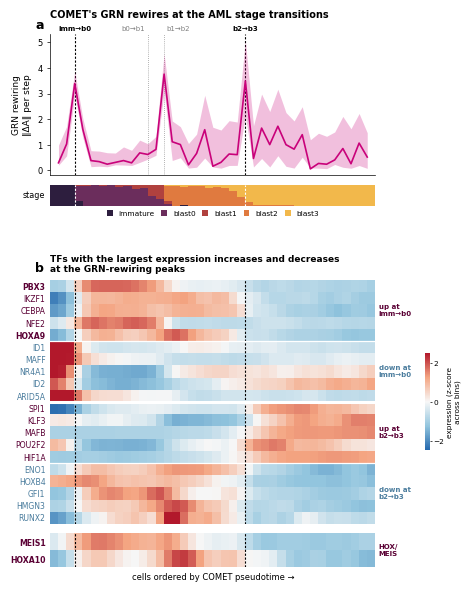

In [20]:
fig = plt.figure(figsize=(5.0, 6.2))
gl = fig.add_gridspec(5, 1, height_ratios=[2.2, 0.32, 0.85, 0.19 * n_rows, 0.19 * max(len(EXTRA), 1) + 0.15], hspace=0.10,
                      left=0.15, right=0.80, top=0.92, bottom=0.06)
burst_column(fig, gl, z=True, cbar_dx=0.10)
fig.savefig(f"{FIG}/fig2b_aml_burst_expression.pdf"); fig.savefig(f"{FIG}/fig2b_aml_burst_expression.png"); plt.show()

## Figure 0 · Fig. 1a and Fig. 2b combined

- **Top:** (a) GRN rewiring along the AML trajectory and (b) the TFs changing expression at its peaks (Fig. 2b), at full width.
- **Bottom:** (c) lineage TF expression and (d) lineage-specific GRN edge gains (Fig. 1a).

Shown at the top of the notebook; saved as `figs_final/fig0_combined.{png,svg,pdf}`.

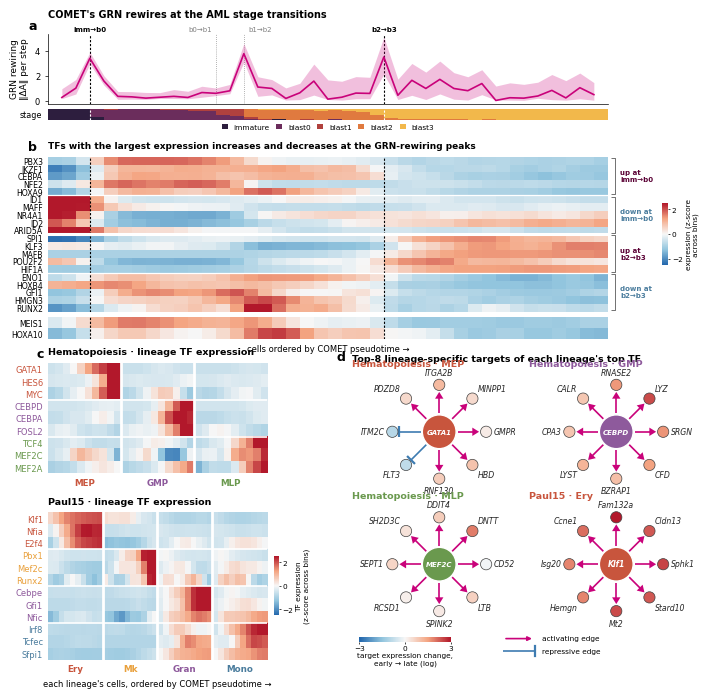

In [21]:
HROWS0 = [1.35, 0.20, 0.50, 0.15 * n_rows, 0.15 * max(len(EXTRA), 1) + 0.12]
HBOT0 = 0.75 + 1.45 * NR_NET                                                                  # bottom block height (in)
fig = plt.figure(figsize=(7.2, HBOT0 + 0.62 * sum(HROWS0)))
outer = fig.add_gridspec(2, 1, height_ratios=[0.62 * sum(HROWS0), HBOT0], hspace=0.14,
                         left=0.08, right=0.99, top=0.965, bottom=0.03)
top = outer[0].subgridspec(1, 2, width_ratios=[1.0, 0.17], wspace=0.0)                       # AML (a, b)
burst_column(fig, top[0].subgridspec(5, 1, height_ratios=HROWS0, hspace=0.10), z=True, cbar_dx=0.075, letters=("a", "b"), plain=True)
bot = outer[1].subgridspec(1, 2, width_ratios=[1.25, 2.0], wspace=0.30)                      # hematopoiesis (c, d)
lineage_heatmaps(fig, bot[0].subgridspec(2, 1, height_ratios=[3, 4], hspace=0.30), "c")
network_block(fig, bot[1], "d", hspace=0.16, ylim=1.34, header=0.06)
for ext in ("png", "svg", "pdf"): fig.savefig(f"{FIG}/fig0_combined.{ext}")
plt.show()

## Outputs

In [22]:
for f in sorted(os.listdir(TAB)): print("tables_final/" + f)
for f in sorted(os.listdir(FIG)): print("figs_final/" + f)

tables_final/aml_burst_explaining_tfs.csv
tables_final/aml_burst_sensitivity.csv
tables_final/aml_burst_tfs.csv
tables_final/aml_burst_tfs_top12.csv
tables_final/aml_rewiring_at_boundaries.csv
tables_final/aml_tfs_at_blast2_blast3.csv
tables_final/aml_tfs_at_immature_blast0.csv
tables_final/branch_edges_hema.csv
tables_final/branch_edges_paul15.csv
tables_final/branch_tf_ranking.csv
tables_final/drivers_hema.csv
tables_final/drivers_paul15.csv
tables_final/known_regulator_recovery.csv
tables_final/module_lineage_specificity.csv
tables_final/outdegree_driver_tests.csv
tables_final/outdegree_specificity_hema.csv
tables_final/outdegree_specificity_paul15.csv
figs_final/.ipynb_checkpoints
figs_final/fig0_combined.pdf
figs_final/fig0_combined.png
figs_final/fig0_combined.svg
figs_final/fig1_revised_drivers_outdegree.pdf
figs_final/fig1_revised_drivers_outdegree.png
figs_final/fig1a_lineage_tfs_branch_edges.pdf
figs_final/fig1a_lineage_tfs_branch_edges.png
figs_final/fig2_aml_burst.pdf
figs_